# Industry Project: Routing Support Tickets with Only a Few Labels (Production-Style)

> **Who is this notebook for?** Beginners who know what a classifier is and want to see how a real team builds one when **almost nothing is labeled**.
> You do not need the math from `01_semi_supervised_learning.ipynb`. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `01_semi_supervised_learning.ipynb`

| `01_semi_supervised_learning.ipynb` | This notebook |
|---|---|
| Explains **how** self-training, label propagation, FixMatch, ... work | Shows **how a support team uses** them on real text |
| Synthetic 2-D points (`make_classification`) | ~3,000 real messages turned into "support tickets" |
| One accuracy number | A **strong supervised baseline first**, repeated over several random label draws, a learning curve, a cost estimate |
| Assumes semi-supervised learning helps | Measures **when it helps and when it does not** (and shows how it can fail) |
| Ends at `fit()` | Ends with a saved model, a **confidence-based routing rule**, and tests |

---

### The business problem

You work at a company that sells computers and software. Customers write support tickets, and each ticket must go to the right **queue** (team):

| Queue | What it handles |
|---|---|
| `sales_orders` | buying / selling equipment, offers, prices |
| `pc_hardware` | PC hardware problems (disks, boards, controllers) |
| `mac_hardware` | Apple Mac hardware problems |
| `linux_x11_software` | X Window / Unix software problems |
| `security` | encryption, keys, privacy |

Today a human **dispatcher** reads every ticket and routes it. That costs about **1 minute per ticket**, and tickets wait in the inbox for hours.

- There are **thousands of old tickets**, but the old system never stored the final queue, so they are **unlabeled**.
- The team leads labeled **150 tickets** by hand in one afternoon.
- A separate **gold set** of later tickets was labeled carefully by QA, **only for evaluation**.

**Your job:** build a router that is as accurate as possible with these few labels, decide whether the unlabeled tickets help, and estimate **how many more labels** would be worth buying.

**Success means:** macro-F1 on the gold set (every queue matters, even small ones), plus a routing rule where confident tickets are routed automatically and unsure ones go to a human.

---

### Table of Contents
1. Setup: imports and one central config
2. Get the tickets (a realistic export)
3. Clean and validate the tickets
4. Simulate the real situation: 150 labels, thousands unlabeled
5. Baselines first: dummy and a strong supervised model
6. Use the unlabeled text for the vocabulary (does it help?)
7. Off-the-shelf self-training (and why it can collapse)
8. Careful pseudo-labeling: per-queue quotas and confidence thresholds
9. Graph-based label spreading
10. Is the gain real? Repeat with different label draws
11. Learning curve: how many labels do we need?
12. Error analysis: which queues get confused?
13. Production: confidence-based routing (auto-route vs human)
14. Save the model with its metadata
15. Serving function with input validation
16. Automated sanity tests
17. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All the important numbers (how many labels we have, confidence thresholds, label cost) live in **one config object**. When the business says "we can afford 300 labels now", you change one line.

In [1]:
# ---- Standard library ----
import json                      # save model metadata as readable text
import logging                   # timestamped status messages instead of print()
import re                        # regular expressions, used to clean text
import tempfile                  # temporary folder for the saved model (we never write into the repo)
import time                      # measure how long things take
import warnings                  # hide noisy library warnings in this tutorial
from dataclasses import dataclass, asdict, field
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import joblib                    # save / load scikit-learn objects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.base import clone                                  # fresh, unfitted copy of a model
from sklearn.datasets import fetch_20newsgroups                 # our source of real text
from sklearn.decomposition import TruncatedSVD                  # compress TF-IDF into dense vectors
from sklearn.dummy import DummyClassifier                       # the "dumb" baseline
from sklearn.feature_extraction.text import TfidfVectorizer     # text -> numbers
from sklearn.linear_model import LogisticRegression             # the workhorse text classifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.semi_supervised import LabelSpreading, SelfTrainingClassifier

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("ticket_router")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    n_labeled: int = 150                 # tickets labeled by hand by the team leads
    min_ticket_chars: int = 30           # shorter tickets are empty / auto-replies -> dropped
    # pseudo-labeling settings (Section 8)
    pl_rounds: int = 10                  # how many self-training rounds
    pl_per_queue: int = 50               # max new pseudo-labels PER QUEUE per round (keeps queues balanced)
    pl_min_confidence: float = 0.30      # never pseudo-label a ticket below this predicted probability
    # business numbers
    cost_per_label_usd: float = 0.80     # ~1 minute of a team lead's time per ticket
    n_repeats: int = 5                   # how many different random label draws we test (Section 10)
    # newsgroup -> support queue mapping (our "ticket queues")
    queues: dict = field(default_factory=lambda: {
        "misc.forsale": "sales_orders",
        "comp.sys.ibm.pc.hardware": "pc_hardware",
        "comp.sys.mac.hardware": "mac_hardware",
        "comp.windows.x": "linux_x11_software",
        "sci.crypt": "security",
    })


CFG = Config()
np.random.seed(CFG.random_state)
log.info("scikit-learn %s", sklearn.__version__)
print(CFG)

2026-10-21 16:44:05,639 | INFO | scikit-learn 1.9.0


Config(random_state=42, n_labeled=150, min_ticket_chars=30, pl_rounds=10, pl_per_queue=50, pl_min_confidence=0.3, cost_per_label_usd=0.8, n_repeats=5, queues={'misc.forsale': 'sales_orders', 'comp.sys.ibm.pc.hardware': 'pc_hardware', 'comp.sys.mac.hardware': 'mac_hardware', 'comp.windows.x': 'linux_x11_software', 'sci.crypt': 'security'})


---
## 2. Get the tickets (a realistic export)

In a company, tickets come from the helpdesk system (Zendesk, Freshdesk, Jira Service Management) via an API or a database export, for example:

```python
# Real-life version (not run here):
# tickets = pd.read_sql("SELECT ticket_id, created_at, body FROM tickets WHERE created_at >= '2026-01-01'", engine)
```

So that this notebook runs **offline**, we use the classic **20 Newsgroups** dataset (already cached by scikit-learn) and pretend each newsgroup is a support queue. These are real messages written by real people: typos, signatures, very short and very long texts. That makes them much closer to real tickets than toy data.

Two important details:
- We remove **headers, footers and quoted replies** (`remove=(...)`). Headers contain the newsgroup name, which would be a perfect "cheat" feature. Real tickets do not tell you their queue either.
- The dataset is split **by date**: the `train` part is older, the `test` part is newer. We use the old part as our **ticket backlog** and the newer part as the **gold evaluation set**. Testing on *later* tickets is honest: in production the router always sees future tickets.

In [2]:
def load_ticket_export(subset: str) -> pd.DataFrame:
    """Load messages from the local scikit-learn cache and shape them like a helpdesk export."""
    raw = fetch_20newsgroups(subset=subset, categories=list(CFG.queues),
                             remove=("headers", "footers", "quotes"),   # no cheating via metadata
                             download_if_missing=False)                 # must already be cached locally
    newsgroup_names = np.array(raw.target_names)[raw.target]           # number -> newsgroup name
    return pd.DataFrame({
        "ticket_id": [f"{subset[:2].upper()}-{i:05d}" for i in range(len(raw.data))],
        "body": raw.data,                                               # the ticket text
        "queue": pd.Series(newsgroup_names).map(CFG.queues).values,     # newsgroup -> queue name
    })


backlog_raw = load_ticket_export("train")   # older tickets: our backlog
gold_raw = load_ticket_export("test")       # newer tickets: QA-labeled gold evaluation set
print(f"Backlog: {len(backlog_raw):,} tickets | Gold set: {len(gold_raw):,} tickets")
print("\nOne example ticket:\n" + "-" * 60)
print(backlog_raw.loc[3, "body"][:500])
print("-" * 60, "\nTrue queue:", backlog_raw.loc[3, "queue"])

Backlog: 2,941 tickets | Gold set: 1,958 tickets

One example ticket:
------------------------------------------------------------

1. You need these resources :
	XTerm*EightBitInput:    true
	XTerm*EightBitOutput:    true

2. In the shell you need to do : 
        stty cs8 -istrip 


Good luck .
Victor .
------------------------------------------------------------ 
True queue: linux_x11_software


---
## 3. Clean and validate the tickets

Real ticket exports contain junk: **empty tickets** (only an attachment), one-line auto-replies, duplicated submissions, and messy whitespace. We fix that with one **function**, so the exact same cleaning runs on next month's export and inside the serving code.

In [3]:
def clean_ticket_text(text: str) -> str:
    """Normalise one ticket body: collapse whitespace and strip leading/trailing spaces."""
    text = re.sub(r"\s+", " ", str(text))       # newlines, tabs, repeated spaces -> one space
    return text.strip()


def clean_tickets(df: pd.DataFrame) -> pd.DataFrame:
    """Return a NEW, cleaned DataFrame (never modifies the input)."""
    df = df.copy()
    df["body"] = df["body"].map(clean_ticket_text)
    too_short = df["body"].str.len() < CFG.min_ticket_chars          # empty tickets / auto-replies
    duplicated = df["body"].duplicated(keep="first")                   # same text submitted twice
    log.info("Dropping %d too-short and %d duplicated tickets", too_short.sum(), (duplicated & ~too_short).sum())
    return df[~too_short & ~duplicated].reset_index(drop=True)


def validate_tickets(df: pd.DataFrame, require_label: bool = True) -> None:
    """A tiny data contract: stop loudly if the export is broken."""
    assert {"ticket_id", "body"} <= set(df.columns), "missing columns"
    assert df["ticket_id"].is_unique, "duplicate ticket ids"
    assert df["body"].str.len().min() >= CFG.min_ticket_chars, "empty tickets slipped through"
    if require_label:
        unknown = set(df["queue"]) - set(CFG.queues.values())
        assert not unknown, f"unknown queues: {unknown}"
    log.info("Data contract passed for %d tickets", len(df))


backlog = clean_tickets(backlog_raw)
gold = clean_tickets(gold_raw)

# Leakage guard: the same text can appear in the backlog AND in the gold set (re-sent tickets,
# copy-pasted messages). Such gold tickets would test the model on text it may have trained on.
overlap = gold["body"].isin(set(backlog["body"]))
log.info("Removing %d gold tickets whose exact text also appears in the backlog", overlap.sum())
gold = gold[~overlap].reset_index(drop=True)

validate_tickets(backlog)
validate_tickets(gold)

summary = pd.DataFrame({"backlog": backlog["queue"].value_counts(), "gold": gold["queue"].value_counts()})
summary.loc["TOTAL"] = summary.sum()
print(summary)
print("\nTicket length in characters (backlog):")
print(backlog["body"].str.len().describe(percentiles=[0.1, 0.5, 0.9]).round(0))

2026-10-21 16:44:18,005 | INFO | Dropping 74 too-short and 18 duplicated tickets


2026-10-21 16:44:18,177 | INFO | Dropping 76 too-short and 11 duplicated tickets


2026-10-21 16:44:18,191 | INFO | Removing 5 gold tickets whose exact text also appears in the backlog


2026-10-21 16:44:18,197 | INFO | Data contract passed for 2849 tickets


2026-10-21 16:44:18,201 | INFO | Data contract passed for 1866 tickets


                    backlog  gold
queue                            
linux_x11_software      575   377
mac_hardware            550   370
pc_hardware             578   381
sales_orders            565   367
security                581   371
TOTAL                  2849  1866

Ticket length in characters (backlog):
count     2849.0
mean      1063.0
std       3634.0
min         31.0
10%        144.0
50%        473.0
90%       1558.0
max      63516.0
Name: body, dtype: float64


**What we learned:** about 3% of the export was empty or duplicated, and a few gold tickets were exact copies of backlog tickets (removed, otherwise the evaluation would be slightly optimistic). In real helpdesks these shares are often much higher. Queues are roughly balanced, and ticket length varies hugely (from one sentence to several pages). The median ticket is short, so the model must work with few words per ticket.

---
## 4. Simulate the real situation: 150 labels, thousands unlabeled

The dataset actually has a label for every backlog ticket. To mimic the company's situation we **hide** almost all of them:

- `labeled_idx`: 150 randomly chosen tickets that the team leads labeled.
- Everything else gets the label **-1**, which is scikit-learn's convention for "unlabeled".

We keep the hidden true labels in a variable called `secret_truth`, **only to grade our methods later** (e.g. "how many pseudo-labels were correct?"). In real life you would not have it; instead you would **audit a random sample** of pseudo-labels by hand.

In [4]:
QUEUES = sorted(CFG.queues.values())                         # fixed order of class names
queue_to_id = {q: i for i, q in enumerate(QUEUES)}            # "pc_hardware" -> 1 ...

texts = backlog["body"].to_numpy()                             # all backlog texts
secret_truth = backlog["queue"].map(queue_to_id).to_numpy()    # HIDDEN labels, used only for grading
gold_texts = gold["body"].to_numpy()
y_gold = gold["queue"].map(queue_to_id).to_numpy()             # gold labels: used only for evaluation


def draw_labeled_subset(n_labels: int, seed: int) -> np.ndarray:
    """Which tickets did the team leads label? (a random sample, as in real life)"""
    rng = np.random.default_rng(seed)
    return rng.choice(len(texts), size=n_labels, replace=False)


labeled_idx = draw_labeled_subset(CFG.n_labeled, CFG.random_state)
y_partial = np.full(len(texts), -1)                            # -1 = unlabeled (sklearn convention)
y_partial[labeled_idx] = secret_truth[labeled_idx]             # reveal only the 150 labeled tickets

print(f"Labeled: {(y_partial != -1).sum()} | Unlabeled: {(y_partial == -1).sum():,}")
print("Labels per queue:", dict(zip(QUEUES, np.bincount(y_partial[labeled_idx], minlength=len(QUEUES)))))

Labeled: 150 | Unlabeled: 2,699
Labels per queue: {'linux_x11_software': np.int64(26), 'mac_hardware': np.int64(27), 'pc_hardware': np.int64(31), 'sales_orders': np.int64(30), 'security': np.int64(36)}


---
## 5. Baselines first: dummy and a strong supervised model

**Rule #1 of semi-supervised learning: build the best possible supervised model on the labeled data first.** Many published "semi-supervised gains" disappear when the supervised baseline is tuned properly (Oliver et al., 2018, *Realistic Evaluation of Deep Semi-Supervised Learning Algorithms*).

Our baseline is the industry standard for text classification:
- **TF-IDF** turns each ticket into a vector of word weights (rare, informative words get high weight).
- **Logistic regression** learns one weight per word per queue. It is fast, robust and easy to explain.

### Which metric?
- **Accuracy**: share of tickets routed correctly.
- **Macro-F1**: the F1 score computed per queue, then averaged. A small queue counts as much as a big one, so a model that ignores the `security` queue is punished. This is our main metric.

We evaluate **only on the gold set**: never on the tickets we trained on.

In [5]:
def make_vectorizer() -> TfidfVectorizer:
    """Same text settings everywhere, so comparisons are fair."""
    return TfidfVectorizer(sublinear_tf=True,       # 10 mentions are not 10x more important than 1
                           min_df=2,                # ignore words seen in only one ticket (typos)
                           max_df=0.8,              # ignore words in >80% of tickets (no information)
                           stop_words="english")    # drop "the", "and", ...


def make_classifier() -> LogisticRegression:
    """Logistic regression tuned for small text datasets (saga = fast solver for sparse data)."""
    return LogisticRegression(C=10, solver="saga", max_iter=300, tol=1e-3)


def evaluate(name: str, model, X_eval, y_eval=y_gold) -> dict:
    """Score a fitted model on the gold set."""
    pred = model.predict(X_eval)
    return {"method": name,
            "macro_f1": round(f1_score(y_eval, pred, average="macro"), 3),
            "accuracy": round(accuracy_score(y_eval, pred), 3)}


results = []

# (a) Dummy: always predicts the most common queue in the labeled sample
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(labeled_idx), 1)), y_partial[labeled_idx])
results.append(evaluate("Dummy (most frequent queue)", dummy, np.zeros((len(y_gold), 1))))

# (b) Strong supervised baseline: vocabulary learned from the 150 labeled tickets only
vec_labeled_only = make_vectorizer().set_params(min_df=1).fit(texts[labeled_idx])   # min_df=1: 150 docs is tiny
baseline = make_classifier().fit(vec_labeled_only.transform(texts[labeled_idx]), y_partial[labeled_idx])
results.append(evaluate("Supervised, 150 labels (vocab from labeled only)", baseline,
                        vec_labeled_only.transform(gold_texts)))
print(f"Vocabulary size learned from 150 tickets: {len(vec_labeled_only.vocabulary_):,} words")
pd.DataFrame(results)

Vocabulary size learned from 150 tickets: 3,829 words


,method,macro_f1,accuracy
0,Dummy (most frequent queue),0.066,0.199
1,"Supervised, 150 labels (vocab from labeled only)",0.707,0.709


The supervised model is far better than the dummy, but far from good. With only 150 tickets it has seen a small vocabulary: any gold ticket using words it never saw is basically a guess.

---
## 6. Use the unlabeled text for the vocabulary (does it help?)

The simplest way to use unlabeled data is **not** to guess labels at all, but to learn the **representation** from it. Here: fit the TF-IDF vocabulary and word weights on **all backlog tickets** (labels are not used, so there is no leakage), then train the classifier on the 150 labeled ones.

In modern stacks the same idea appears as "use a pretrained embedding model" or "continue pre-training a language model on your own unlabeled tickets", where it is often a big win. Let's see whether the simple TF-IDF version helps here.

In [6]:
vectorizer = make_vectorizer().fit(texts)            # learns vocabulary + IDF from ALL backlog tickets (no labels used)
X_all = vectorizer.transform(texts)                   # every backlog ticket as a TF-IDF vector
X_gold = vectorizer.transform(gold_texts)
print(f"Vocabulary size learned from {len(texts):,} tickets: {len(vectorizer.vocabulary_):,} words")

supervised = make_classifier().fit(X_all[labeled_idx], y_partial[labeled_idx])
results.append(evaluate("Supervised, 150 labels (vocab from ALL tickets)", supervised, X_gold))
pd.DataFrame(results)

Vocabulary size learned from 2,849 tickets: 13,375 words


,method,macro_f1,accuracy
0,Dummy (most frequent queue),0.066,0.199
1,"Supervised, 150 labels (vocab from labeled only)",0.707,0.709
2,"Supervised, 150 labels (vocab from ALL tickets)",0.679,0.683


Compare the last two rows: **it did not help, it even hurt a little.** Why? The bigger vocabulary contains ~10,000 words that none of the 150 labeled tickets use, so the classifier has no weight for them. They only dilute each ticket's vector (TF-IDF vectors are normalised to length 1), which weakens the words the model *does* know. We check this again over several label draws in Section 10.

Lesson: "using unlabeled data" is not automatically good; **measure it**. The large vocabulary becomes useful once pseudo-labeled tickets give the model a chance to learn weights for those extra words (Section 8). From here on, **all** methods use this shared vectorizer.

---
## 7. Off-the-shelf self-training (and why it can collapse)

**Self-training** (also called pseudo-labeling):
1. Train on the labeled tickets.
2. Predict the unlabeled tickets.
3. Treat predictions with probability above a **threshold** as if they were true labels ("pseudo-labels").
4. Retrain and repeat.

scikit-learn has this built in: `SelfTrainingClassifier`. Let's try it with a few thresholds and look at **how many pseudo-labels** it added.

In [7]:
self_training_rows = []
for threshold in [0.5, 0.7, 0.9]:
    st = SelfTrainingClassifier(make_classifier(), threshold=threshold, max_iter=10)
    st.fit(X_all, y_partial)                                       # -1 entries are treated as unlabeled
    n_added = int((st.labeled_iter_ > 0).sum())                    # labeled_iter_ > 0 means "pseudo-labeled"
    row = evaluate(f"SelfTrainingClassifier (threshold={threshold})", st, X_gold)
    row["pseudo_labels_added"] = n_added
    if n_added:                                                    # grading with the hidden truth (simulation only)
        added = st.labeled_iter_ > 0
        row["pseudo_label_accuracy"] = round((st.transduction_[added] == secret_truth[added]).mean(), 3)
        row["share_of_biggest_queue"] = round(np.bincount(st.transduction_[added]).max() / n_added, 2)
    self_training_rows.append(row)

pd.DataFrame(self_training_rows)

,method,macro_f1,accuracy,pseudo_labels_added,pseudo_label_accuracy,share_of_biggest_queue
0,SelfTrainingClassifier (threshold=0.5),0.492,0.531,2655,0.592,0.52
1,SelfTrainingClassifier (threshold=0.7),0.066,0.199,2697,0.207,0.99
2,SelfTrainingClassifier (threshold=0.9),0.679,0.683,0,NaN,NaN


Read this table carefully, it shows the two classic failure modes:

- **High threshold:** with only 150 labels the model is rarely *very* sure (5 queues, few words), so few or no tickets pass the bar and nothing changes.
- **Low threshold:** many tickets pass, but the pseudo-labels are often wrong **and lopsided**: one queue can grab a large share of all pseudo-labels (`share_of_biggest_queue`). The next model learns from those mistakes, becomes even more biased, and the errors snowball. This is called **confirmation bias**, and it can make the result *worse than the baseline*.

The scikit-learn example "Effect of varying threshold for self-training" shows the same trade-off. Production teams therefore add guard rails, which we build next.

---
## 8. Careful pseudo-labeling: per-queue quotas and confidence thresholds

Three guard rails that practitioners use (they also appear in modern methods such as FixMatch and curriculum pseudo-labeling):

1. **Per-queue quota:** in each round, accept at most `pl_per_queue` new pseudo-labels **per queue**. No queue can take over.
2. **Confidence threshold:** never accept a pseudo-label whose probability is below `pl_min_confidence`, and within each queue take the **most confident** first.
3. **Gradual rounds:** add a bit, retrain, repeat. Later rounds use a better model.

Plus one more rule for honesty: **pseudo-labels are never used for evaluation**, only the human gold set is.

In [8]:
def pseudo_label_training(X, y_partial, rounds=CFG.pl_rounds, per_queue=CFG.pl_per_queue,
                          min_confidence=CFG.pl_min_confidence, base_model=None, verbose=False):
    """Class-balanced self-training. Returns (final_model, labels_used, history).

    labels_used has the human labels, the accepted pseudo-labels, and -1 for still-unlabeled tickets.
    """
    base_model = base_model if base_model is not None else make_classifier()
    labels = y_partial.copy()                                       # we will fill in pseudo-labels here
    is_pseudo = np.zeros(len(labels), dtype=bool)                   # remember which labels are guesses
    model = clone(base_model).fit(X[labels != -1], labels[labels != -1])
    history = []
    for round_id in range(1, rounds + 1):
        unlabeled = np.flatnonzero(labels == -1)                   # tickets still without a label
        if len(unlabeled) == 0:
            break
        proba = model.predict_proba(X[unlabeled])                   # probability for each queue
        guess = model.classes_[proba.argmax(axis=1)]                # most likely queue
        confidence = proba.max(axis=1)                              # how sure the model is
        accepted = []
        for queue_id in model.classes_:                             # quota PER QUEUE
            candidates = np.flatnonzero((guess == queue_id) & (confidence >= min_confidence))
            best_first = candidates[np.argsort(-confidence[candidates])][:per_queue]
            accepted.extend(best_first)
        if not accepted:                                            # nothing confident enough: stop
            break
        accepted = np.array(accepted)
        labels[unlabeled[accepted]] = guess[accepted]               # write the pseudo-labels
        is_pseudo[unlabeled[accepted]] = True
        model = clone(base_model).fit(X[labels != -1], labels[labels != -1])   # retrain on humans + pseudo
        history.append({"round": round_id, "added": len(accepted), "total_pseudo": int(is_pseudo.sum()),
                        "min_conf_accepted": round(float(confidence[accepted].min()), 2)})
    return model, labels, is_pseudo, pd.DataFrame(history)


t0 = time.perf_counter()
pl_model, pl_labels, pl_is_pseudo, pl_history = pseudo_label_training(X_all, y_partial)
log.info("Pseudo-labeling finished in %.1fs", time.perf_counter() - t0)

print(pl_history.to_string(index=False))
# Grade the pseudo-labels with the hidden truth (in real life: hand-audit a random sample of ~50)
print(f"\nPseudo-labels: {pl_is_pseudo.sum():,} | correct: {(pl_labels[pl_is_pseudo] == secret_truth[pl_is_pseudo]).mean():.1%}")

row = evaluate("Pseudo-labeling with per-queue quota", pl_model, X_gold)
row["pseudo_labels_added"] = int(pl_is_pseudo.sum())
results.append(row)
pd.DataFrame(results)

2026-10-21 16:44:38,048 | INFO | Pseudo-labeling finished in 4.5s


 round  added  total_pseudo  min_conf_accepted
     1    250           250               0.42
     2    250           500               0.61
     3    250           750               0.65
     4    250          1000               0.59
     5    250          1250               0.61
     6    250          1500               0.58
     7    250          1750               0.51
     8    250          2000               0.47
     9    250          2250               0.42
    10    250          2500               0.30

Pseudo-labels: 2,500 | correct: 86.3%


,method,macro_f1,accuracy,pseudo_labels_added
0,Dummy (most frequent queue),0.066,0.199,NaN
1,"Supervised, 150 labels (vocab from labeled only)",0.707,0.709,NaN
2,"Supervised, 150 labels (vocab from ALL tickets)",0.679,0.683,NaN
3,Pseudo-labeling with per-queue quota,0.793,0.793,2500.0


With the guard rails, pseudo-labeling adds 2,500 tickets, about 86% of them **correctly** labeled, and the gold macro-F1 jumps from ~0.68-0.71 (supervised) to ~0.79. Notice that every queue received exactly 50 per round, so no queue could take over. The pseudo-labels are not perfect (about 1 in 7 is wrong), yet the model still gains: many mostly-correct examples teach it far more vocabulary than 150 perfect ones. Also notice that the minimum accepted confidence falls in the last rounds: the "easy" tickets are used up, and later rounds accept harder (riskier) ones. That is why the number of rounds is a setting worth tuning.

> **How would you check pseudo-label quality without `secret_truth`?** Take a random sample of ~50 pseudo-labeled tickets, have a human label them, and compute the agreement. If it is low, lower `pl_per_queue` or raise `pl_min_confidence`.

---
## 9. Graph-based label spreading

**Label spreading** builds a **similarity graph**: each ticket is connected to its *k* most similar tickets. Labels then "flow" from the 150 labeled tickets along the edges, like ink spreading on paper. It relies on the **cluster assumption**: similar tickets share a queue.

Graph methods need dense, compact vectors, so we first compress TF-IDF with **TruncatedSVD** (also called LSA) to 100 dimensions. `kernel="knn"` keeps the graph sparse and the memory small.

In [9]:
svd = make_pipeline(TruncatedSVD(n_components=100, random_state=CFG.random_state), Normalizer())
Z_all = svd.fit_transform(X_all)                      # 100-dim "topic" vectors, learned without labels
Z_gold = svd.transform(X_gold)

spreading = LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2, max_iter=100)
spreading.fit(Z_all, y_partial)                       # -1 = unlabeled; labels spread over the kNN graph
results.append(evaluate("Label spreading (kNN graph on SVD vectors)", spreading, Z_gold))

# A common production trick: use the spread labels to train the normal text classifier (fast to serve)
spread_then_lr = make_classifier().fit(X_all, spreading.transduction_)
results.append(evaluate("Label spreading -> logistic regression", spread_then_lr, X_gold))
unl = y_partial == -1
print(f"Accuracy of spread labels on the unlabeled backlog: {(spreading.transduction_[unl] == secret_truth[unl]).mean():.1%}")
pd.DataFrame(results)

Accuracy of spread labels on the unlabeled backlog: 70.8%


,method,macro_f1,accuracy,pseudo_labels_added
0,Dummy (most frequent queue),0.066,0.199,NaN
1,"Supervised, 150 labels (vocab from labeled only)",0.707,0.709,NaN
2,"Supervised, 150 labels (vocab from ALL tickets)",0.679,0.683,NaN
3,Pseudo-labeling with per-queue quota,0.793,0.793,2500.0
4,Label spreading (kNN graph on SVD vectors),0.734,0.737,NaN
5,Label spreading -> logistic regression,0.737,0.739,NaN


Label spreading also uses the unlabeled tickets. It beats the supervised baseline a little, but it is clearly worse than careful pseudo-labeling: about 29% of the labels it spreads over the backlog are wrong (vs ~14% for the quota-based pseudo-labels). In a 100-dimensional summary of text, the "neighbours" of a ticket are often from a different queue (Mac and PC hardware tickets look very alike), so the **cluster assumption is only partly true**. This is a typical real-world outcome: graph methods shine when classes form clean clusters (e.g. images with good embeddings), less so on short, overlapping texts.

---
## 10. Is the gain real? Repeat with different label draws

Everything above used **one** random set of 150 labeled tickets. With so few labels, results swing a lot depending on *which* tickets were labeled. Before telling your manager "pseudo-labeling adds X points", repeat the whole experiment with several random draws and look at the **paired difference** (same draw, two methods).

In [10]:
def run_methods_for_draw(n_labels: int, seed: int, with_small_vocab: bool = False) -> dict:
    """Train the main methods on one random draw of labeled tickets and return gold macro-F1."""
    idx = draw_labeled_subset(n_labels, seed)
    y_part = np.full(len(texts), -1)
    y_part[idx] = secret_truth[idx]
    out = {"seed": seed, "n_labels": n_labels}
    out["supervised"] = f1_score(y_gold, make_classifier().fit(X_all[idx], y_part[idx]).predict(X_gold), average="macro")
    if with_small_vocab:                                    # Section 6 variant: vocabulary from labeled tickets only
        vec_small = make_vectorizer().set_params(min_df=1).fit(texts[idx])
        clf_small = make_classifier().fit(vec_small.transform(texts[idx]), y_part[idx])
        out["supervised_small_vocab"] = f1_score(y_gold, clf_small.predict(vec_small.transform(gold_texts)), average="macro")
    model, *_ = pseudo_label_training(X_all, y_part)
    out["pseudo_labeling"] = f1_score(y_gold, model.predict(X_gold), average="macro")
    ls = LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2, max_iter=100).fit(Z_all, y_part)
    out["label_spreading"] = f1_score(y_gold, ls.predict(Z_gold), average="macro")
    return out


t0 = time.perf_counter()
repeats = pd.DataFrame([run_methods_for_draw(CFG.n_labeled, seed, with_small_vocab=True) for seed in range(CFG.n_repeats)])
log.info("%d repeats done in %.0fs", CFG.n_repeats, time.perf_counter() - t0)

repeats["gain_pseudo_vs_supervised"] = repeats["pseudo_labeling"] - repeats["supervised"]
print(repeats.round(3).to_string(index=False))
summary_150 = repeats[["supervised_small_vocab", "supervised", "pseudo_labeling", "label_spreading",
                       "gain_pseudo_vs_supervised"]].agg(["mean", "std", "min"])
print("\n", summary_150.round(3))

2026-10-21 16:45:33,383 | INFO | 5 repeats done in 36s


 seed  n_labels  supervised  supervised_small_vocab  pseudo_labeling  label_spreading  gain_pseudo_vs_supervised
    0       150       0.607                   0.642            0.781            0.690                      0.174
    1       150       0.707                   0.707            0.780            0.696                      0.073
    2       150       0.705                   0.712            0.795            0.718                      0.091
    3       150       0.682                   0.684            0.800            0.689                      0.118
    4       150       0.653                   0.700            0.799            0.658                      0.146

       supervised_small_vocab  supervised  pseudo_labeling  label_spreading  \
mean                   0.689       0.671            0.791            0.690   
std                    0.028       0.042            0.010            0.021   
min                    0.642       0.607            0.780            0.658   

      g

How to read this like a professional:
- Look at the **minimum** of the paired gain, not only the mean. Here pseudo-labeling beats the supervised model in **every one of the 5 draws** (smallest gain ≈ +0.07 macro-F1, average ≈ +0.12), so the effect is robust. If the gain were sometimes negative, you would need stronger guard rails or more labels.
- The **std** of the supervised baseline (≈ 0.03-0.04) tells you how much luck there is in "which 150 tickets were labeled". Pseudo-labeling is not only better on average, it is also much **more stable** across draws (std ≈ 0.01).
- The Section 6 finding holds on average: the plain supervised model is slightly better with the small, labeled-only vocabulary (`supervised_small_vocab`) than with the shared vocabulary. The large vocabulary pays off only together with pseudo-labels.
- Label spreading is roughly on par with the supervised baseline here, so it would not be worth its extra complexity.

---
## 11. Learning curve: how many labels do we need?

The most useful chart for a manager: **quality vs number of labels**, for the plain supervised model and for pseudo-labeling. It answers:
- "If we pay for 300 more labels, how much better does the router get?"
- "Does semi-supervised learning still matter once we have many labels?"

The dashed line is the model trained on **all** backlog labels (what we would get after labeling everything, ~2,700 tickets).

2026-10-21 16:47:36,203 | INFO | Learning curve done in 123s


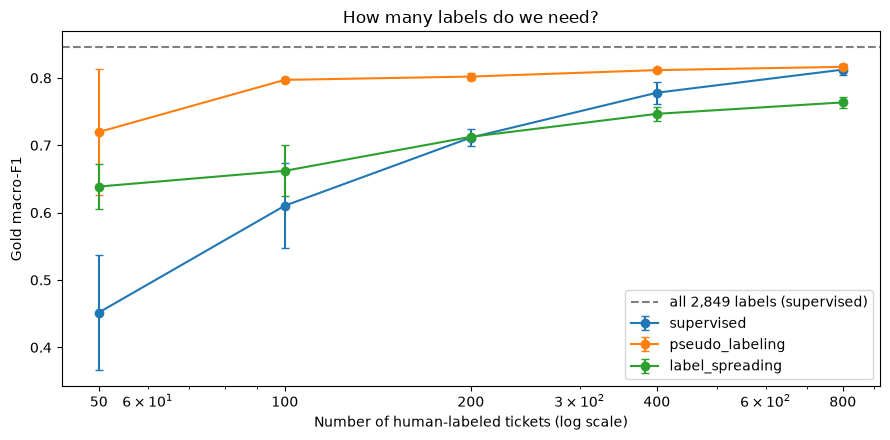

          supervised  pseudo_labeling  label_spreading  gain_from_pseudo  \
n_labels                                                                   
50             0.452            0.720            0.639             0.268   
100            0.610            0.797            0.662             0.187   
200            0.711            0.802            0.713             0.091   
400            0.778            0.812            0.747             0.034   
800            0.812            0.816            0.764             0.004   

          label_cost_usd  
n_labels                  
50                  40.0  
100                 80.0  
200                160.0  
400                320.0  
800                640.0  

All 2,849 labels (supervised): macro-F1 = 0.845, cost ~$2,279


In [11]:
label_budgets = [50, 100, 200, 400, 800]
n_seeds_curve = 3                                         # fewer repeats to keep the runtime small
t0 = time.perf_counter()
curve = pd.DataFrame([run_methods_for_draw(n, seed) for n in label_budgets for seed in range(n_seeds_curve)])
log.info("Learning curve done in %.0fs", time.perf_counter() - t0)

full_model = make_classifier().fit(X_all, secret_truth)    # upper bound: every backlog ticket labeled
full_f1 = f1_score(y_gold, full_model.predict(X_gold), average="macro")

curve_mean = curve.groupby("n_labels")[["supervised", "pseudo_labeling", "label_spreading"]].mean()
curve_std = curve.groupby("n_labels")[["supervised", "pseudo_labeling", "label_spreading"]].std()

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, color in [("supervised", "tab:blue"), ("pseudo_labeling", "tab:orange"), ("label_spreading", "tab:green")]:
    ax.errorbar(curve_mean.index, curve_mean[col], yerr=curve_std[col], marker="o", capsize=3, label=col, color=color)
ax.axhline(full_f1, color="grey", ls="--", label=f"all {len(texts):,} labels (supervised)")
ax.set_xscale("log"); ax.set_xticks(label_budgets); ax.set_xticklabels(label_budgets)
ax.set_xlabel("Number of human-labeled tickets (log scale)"); ax.set_ylabel("Gold macro-F1")
ax.set_title("How many labels do we need?"); ax.legend(); plt.tight_layout(); plt.show()

table = curve_mean.round(3)
table["gain_from_pseudo"] = (curve_mean["pseudo_labeling"] - curve_mean["supervised"]).round(3)
table["label_cost_usd"] = [n * CFG.cost_per_label_usd for n in table.index]
print(table)
print(f"\nAll {len(texts):,} labels (supervised): macro-F1 = {full_f1:.3f}, cost ~${len(texts) * CFG.cost_per_label_usd:,.0f}")

**The business reading of this chart:**
- With **few labels** (50 to 200), pseudo-labeling gives a large boost: with 100 labels it scores about as well as the supervised model with 400 labels. It is like getting several hundred labels for free.
- As the number of labels grows, the gain **shrinks**: about +0.03 at 400 labels and almost nothing at 800. From there on, the extra complexity (more code, more things to monitor, risk of confirmation bias) is no longer worth it.
- Label spreading helps only at the very smallest budgets and falls behind the plain supervised model from ~200 labels on.
- Labels are cheap compared to engineering time. At ~$0.80 per label, **800 labels cost about $640**, and the plain supervised model trained on them (~0.81) is already slightly better than pseudo-labeling with 150 labels (~0.79). A sensible plan is therefore: *use pseudo-labeling now to launch quickly, and keep buying labels* (ideally chosen with active learning, see `../13_active_learning/`) until the simple supervised model is good enough on its own.

---
## 12. Error analysis: which queues get confused?

A single number hides *where* the model fails. The **confusion matrix** shows true queues (rows) against predicted queues (columns).

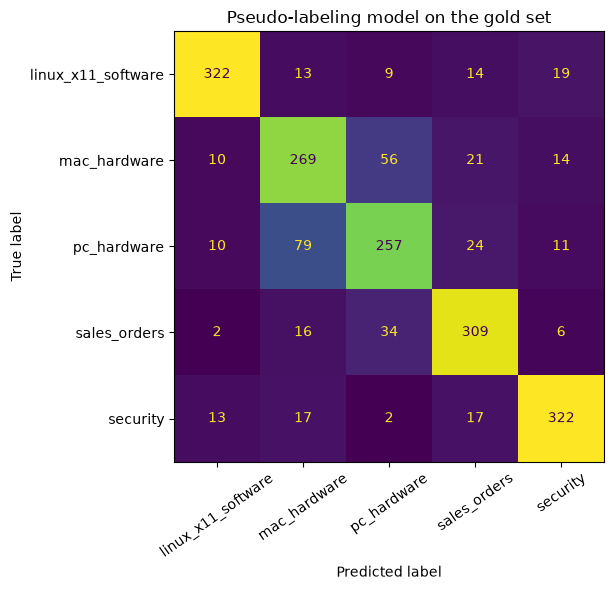

                    precision    recall  f1-score   support

linux_x11_software      0.902     0.854     0.877       377
      mac_hardware      0.683     0.727     0.704       370
       pc_hardware      0.718     0.675     0.696       381
      sales_orders      0.803     0.842     0.822       367
          security      0.866     0.868     0.867       371

          accuracy                          0.793      1866
         macro avg      0.794     0.793     0.793      1866
      weighted avg      0.794     0.793     0.793      1866



In [12]:
gold_pred = pl_model.predict(X_gold)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_gold, gold_pred), display_labels=QUEUES).plot(
    ax=ax, colorbar=False, xticks_rotation=35)
ax.set_title("Pseudo-labeling model on the gold set")
plt.tight_layout(); plt.show()
print(classification_report(y_gold, gold_pred, target_names=QUEUES, digits=3))

As expected, **`pc_hardware` and `mac_hardware` are the most confused pair**: both talk about disks, drives, memory and monitors. Business options in real life:
- merge them into one `hardware` queue (often the pragmatic answer),
- add a structured field to the ticket form ("Which computer do you use?"),
- or spend the next labeling budget specifically on these two queues.

---
## 13. Production: confidence-based routing (auto-route vs human)

A router does not have to decide every ticket. A standard design is:

- If the model's confidence is **≥ T**, route automatically.
- Otherwise, send the ticket to the human dispatcher (the "triage" queue).

Raising *T* means **fewer automatic decisions** (coverage) but **fewer mistakes** among them (precision). We pick *T* on the gold set here for illustration; in a real project use a separate validation set, because the gold set should stay a final exam.

In [13]:
gold_proba = pl_model.predict_proba(X_gold)
gold_conf = gold_proba.max(axis=1)                       # confidence of the top queue
gold_guess = pl_model.classes_[gold_proba.argmax(axis=1)]

rows = []
for threshold in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    auto = gold_conf >= threshold                         # tickets that would be auto-routed
    rows.append({"threshold": threshold,
                 "auto_routed_share": round(auto.mean(), 3),
                 "accuracy_of_auto_routed": round((gold_guess[auto] == y_gold[auto]).mean(), 3) if auto.any() else np.nan,
                 "dispatcher_minutes_saved_per_1000": int(auto.mean() * 1000)})   # 1 minute per ticket
routing_table = pd.DataFrame(rows)
print(routing_table.to_string(index=False))

 threshold  auto_routed_share  accuracy_of_auto_routed  dispatcher_minutes_saved_per_1000
       0.0              1.000                    0.793                               1000
       0.3              0.980                    0.802                                980
       0.4              0.899                    0.834                                899
       0.5              0.805                    0.871                                805
       0.6              0.714                    0.902                                714
       0.7              0.621                    0.926                                620
       0.8              0.506                    0.940                                506


This table is what you show the support manager. Routing *everything* automatically would be right only ~79% of the time, which is not acceptable. Suppose the manager asks for "**about 90% correct on the tickets we auto-route**": the table shows that a threshold of **0.6** delivers ~90% accuracy while still auto-routing ~70% of tickets, i.e. ~700 dispatcher minutes saved per 1,000 tickets. Everything below the threshold still goes to a human. We use 0.6 below.

> Warning: logistic regression trained with pseudo-labels can be **over-confident**. Before using probabilities this way in production, check calibration on a labeled validation set (see `../01_supervised/13_model_calibration.ipynb`).

---
## 14. Save the model with its metadata

We save **one pipeline** (vectorizer + classifier) so the serving code cannot accidentally use a different vectorizer. The metadata records how many labels were human vs pseudo: an auditor will ask.

We save into a temporary folder so this tutorial doesn't add files to the repository. In a real project this would be `models/ticket_router/v1/`.

In [14]:
CHOSEN_THRESHOLD = 0.6                                       # chosen from the routing table above
router_pipeline = make_pipeline(vectorizer, pl_model)        # both steps are already fitted

ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="ticket_router_"))   # real life: models/ticket_router/v1/
joblib.dump(router_pipeline, ARTIFACT_DIR / "router.joblib")
chosen_row = routing_table.set_index("threshold").loc[CHOSEN_THRESHOLD]
metadata = {
    "model_name": "ticket_router",
    "model_version": "1.0.0",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "queues": QUEUES,
    "n_human_labels": int((y_partial != -1).sum()),
    "n_pseudo_labels": int(pl_is_pseudo.sum()),
    "pseudo_label_settings": {"rounds": CFG.pl_rounds, "per_queue": CFG.pl_per_queue,
                              "min_confidence": CFG.pl_min_confidence},
    "auto_route_threshold": CHOSEN_THRESHOLD,
    "gold_metrics": {"macro_f1": round(f1_score(y_gold, gold_pred, average="macro"), 4),
                     "auto_routed_share": float(chosen_row["auto_routed_share"]),
                     "accuracy_of_auto_routed": float(chosen_row["accuracy_of_auto_routed"])},
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:15s} {f.stat().st_size / 1024:8.1f} KB")
print(json.dumps(metadata["gold_metrics"], indent=2))

metadata.json        0.5 KB
router.joblib      792.6 KB
{
  "macro_f1": 0.7931,
  "auto_routed_share": 0.714,
  "accuracy_of_auto_routed": 0.902
}


---
## 15. Serving function with input validation

The helpdesk calls the router via an API for every new ticket. The serving code:
1. loads the pipeline **once**,
2. validates the input (Pydantic, as used by FastAPI),
3. applies **the same cleaning** as training,
4. returns either a queue or `"human_triage"`, plus the confidence and the top alternatives (useful for the dispatcher UI).

In [15]:
from pydantic import BaseModel, Field, ValidationError


class TicketIn(BaseModel):
    """The shape of a ticket the router accepts."""
    ticket_id: str = Field(min_length=1)
    body: str = Field(min_length=1, max_length=50_000)       # reject empty and absurdly long payloads


class TicketRouter:
    def __init__(self, artifact_dir: Path):
        self.pipeline = joblib.load(artifact_dir / "router.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        self.queues = self.meta["queues"]
        self.threshold = self.meta["auto_route_threshold"]

    def route(self, payload: dict) -> dict:
        ticket = TicketIn(**payload)                             # raises ValidationError on bad input
        text = clean_ticket_text(ticket.body)                    # SAME cleaning as in training
        if len(text) < CFG.min_ticket_chars:                     # too little text to decide
            return {"ticket_id": ticket.ticket_id, "queue": "human_triage", "reason": "too short"}
        proba = self.pipeline.predict_proba([text])[0]
        order = np.argsort(-proba)                               # best queue first
        top = self.queues[order[0]]
        confident = proba[order[0]] >= self.threshold
        return {"ticket_id": ticket.ticket_id,
                "queue": top if confident else "human_triage",
                "confidence": round(float(proba[order[0]]), 3),
                "suggestions": [(self.queues[i], round(float(proba[i]), 3)) for i in order[:3]],
                "model_version": self.meta["model_version"]}


router = TicketRouter(ARTIFACT_DIR)
examples = [
    {"ticket_id": "NEW-1", "body": "My hard drive is not recognized after I installed a new IDE controller card in my 486 PC."},
    {"ticket_id": "NEW-2", "body": "Selling a used laser printer, barely used, $150 or best offer. Shipping included."},
    {"ticket_id": "NEW-3", "body": "Is the key escrow scheme safe? Who holds the keys for the encryption chip?"},
    {"ticket_id": "NEW-4", "body": "Hello, it does not work. Please help."},
    {"ticket_id": "NEW-5", "body": "ok"},
]
for ex in examples:
    print(router.route(ex))

try:
    router.route({"ticket_id": "", "body": ""})                  # broken payload from the helpdesk
except ValidationError as err:
    print(f"\nRejected bad request with {err.error_count()} validation errors")

{'ticket_id': 'NEW-1', 'queue': 'pc_hardware', 'confidence': 1.0, 'suggestions': [('pc_hardware', 1.0), ('sales_orders', 0.0), ('mac_hardware', 0.0)], 'model_version': '1.0.0'}
{'ticket_id': 'NEW-2', 'queue': 'sales_orders', 'confidence': 0.995, 'suggestions': [('sales_orders', 0.995), ('mac_hardware', 0.004), ('security', 0.001)], 'model_version': '1.0.0'}
{'ticket_id': 'NEW-3', 'queue': 'security', 'confidence': 0.998, 'suggestions': [('security', 0.998), ('sales_orders', 0.001), ('linux_x11_software', 0.0)], 'model_version': '1.0.0'}
{'ticket_id': 'NEW-4', 'queue': 'human_triage', 'confidence': 0.517, 'suggestions': [('linux_x11_software', 0.517), ('mac_hardware', 0.329), ('pc_hardware', 0.126)], 'model_version': '1.0.0'}
{'ticket_id': 'NEW-5', 'queue': 'human_triage', 'reason': 'too short'}

Rejected bad request with 2 validation errors


Notice how the vague ticket ("it does not work") gets low confidence and goes to a human. That is exactly the behaviour we want.

---
## 16. Automated sanity tests

These would live in `tests/test_ticket_router.py` and run in CI on every change (see `../../15_MLOps/07_testing_in_ml/`).

In [16]:
def test_beats_supervised_baseline():
    """Quality gate: the semi-supervised model must beat the plain supervised one on the gold set."""
    sup_f1 = f1_score(y_gold, supervised.predict(X_gold), average="macro")
    assert metadata["gold_metrics"]["macro_f1"] > sup_f1, (metadata["gold_metrics"]["macro_f1"], sup_f1)


def test_pseudo_labels_never_in_gold():
    """Leakage guard: gold tickets must not appear in the training backlog."""
    assert not set(gold["body"]) & set(backlog["body"][pl_is_pseudo | (y_partial != -1)])


def test_router_output_contract():
    """Every answer has a valid queue name and a probability between 0 and 1."""
    out = router.route(examples[0])
    assert out["queue"] in QUEUES + ["human_triage"]
    assert 0.0 <= out["confidence"] <= 1.0


def test_vague_ticket_goes_to_human():
    """Behavioural test: a content-free ticket should not be auto-routed."""
    assert router.route(examples[3])["queue"] == "human_triage"


for test in [test_beats_supervised_baseline, test_pseudo_labels_never_in_gold,
             test_router_output_contract, test_vague_ticket_goes_to_human]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_beats_supervised_baseline
PASSED  test_pseudo_labels_never_in_gold
PASSED  test_router_output_contract
PASSED  test_vague_ticket_goes_to_human


---
## 17. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Strong baseline first | TF-IDF + logistic regression on the 150 labels | Every SSL project; avoids fake gains |
| Use unlabeled data for representation | Vocabulary / IDF / SVD learned from the whole backlog | Embeddings, domain-adaptive pre-training |
| Self-training with guard rails | Per-queue quota + confidence threshold + rounds | Ticket routing, intent detection, document tagging |
| Know the failure mode | Off-the-shelf threshold self-training can collapse | Any pseudo-labeling pipeline |
| Graph methods | Label spreading on a kNN graph | Works best when classes form clean clusters |
| Honest evaluation | Separate, later, human-labeled gold set; repeated label draws | Avoid lucky single runs |
| Learning curve + cost | Macro-F1 vs labels and dollars | Deciding the labeling budget |
| Confidence routing | Auto-route above a threshold, human below | Human-in-the-loop production systems |
| Traceability | Metadata: human vs pseudo labels, thresholds | Audits, debugging |

**When does semi-supervised learning help?** When labels are few (tens to a few hundred), the unlabeled data comes from the **same distribution**, and the model's confident predictions are **mostly right**. It helps less (or hurts) when you already have many labels, when classes overlap heavily, or when pseudo-labels are added without quotas and checks.

### Practice exercises
1. Set `pl_per_queue=200` and `pl_min_confidence=0.0` in the config. What happens to pseudo-label accuracy and gold macro-F1?
2. Replace TF-IDF + SVD with sentence embeddings (see `../../07_NLP/09_sentence_embeddings_advanced.ipynb`) and rerun label spreading. Does the cluster assumption hold better?
3. Instead of 150 *random* labels, pick the 150 tickets closest to k-means cluster centres (a "diverse" cold start). Does the supervised baseline improve?
4. Add a 6th queue that has **no** labeled tickets. What does pseudo-labeling do with those tickets? (Answer: it forces them into the 5 known queues; real systems need an "other" class or out-of-distribution detection.)

### Resources
- scikit-learn example, *Semi-supervised Classification on a Text Dataset* (20 newsgroups, SelfTrainingClassifier, LabelSpreading): https://scikit-learn.org/stable/auto_examples/semi_supervised/plot_semi_supervised_newsgroups.html
- scikit-learn example, *Effect of varying threshold for self-training*: https://scikit-learn.org/stable/auto_examples/semi_supervised/plot_self_training_varying_threshold.html
- scikit-learn user guide, *Semi-supervised learning*: https://scikit-learn.org/stable/modules/semi_supervised.html
- Oliver et al. (2018), *Realistic Evaluation of Deep Semi-Supervised Learning Algorithms* (why strong baselines matter): https://arxiv.org/abs/1804.09170
- Sohn et al. (2020), *FixMatch* (confidence-threshold pseudo-labeling in deep learning): https://arxiv.org/abs/2001.07685

### Related notebooks
- Theory of the methods: `01_semi_supervised_learning.ipynb`
- Choosing *which* tickets to label next: `../13_active_learning/01_active_learning.ipynb` and `../13_active_learning/02_industry_labeling_budget_optimization.ipynb`
- Text classification basics: `../../07_NLP/03_text_classification.ipynb`
- Probability calibration: `../01_supervised/13_model_calibration.ipynb`